In [1]:
# =====================================================
# APPLICATION 2: MATHEMATICAL EXPRESSION VALIDATOR
# PDA AND CFG IMPLEMENTATION
# =====================================================

import re

# STEP 1: Define CFG

grammar = {
    'E': [['T', 'R']],
    'R': [['+', 'T', 'R'], ['-', 'T', 'R'], []],
    'T': [['F', 'U']],
    'U': [['*', 'F', 'U'], ['/', 'F', 'U'], []],
    'F': [['(', 'E', ')'], ['id']]
}

nonterminals = set(grammar.keys())

# STEP 2: Tokenize input

def tokenize(expression):

    expression = expression.replace(" ", "")

    tokens = re.findall(r'\d+|[()+*/-]|.', expression)

    if ''.join(tokens) != expression:
        return None

    return ['id' if token.isdigit() else token
            for token in tokens]


# STEP 3: Define production selection

def get_production(symbol, lookahead):

    if symbol == 'E':
        if lookahead in ('id', '('):
            return ['T', 'R']

    elif symbol == 'R':
        if lookahead == '+':
            return ['+', 'T', 'R']
        if lookahead == '-':
            return ['-', 'T', 'R']
        if lookahead in (')', '$'):
            return []

    elif symbol == 'T':
        if lookahead in ('id', '('):
            return ['F', 'U']

    elif symbol == 'U':
        if lookahead == '*':
            return ['*', 'F', 'U']
        if lookahead == '/':
            return ['/', 'F', 'U']
        if lookahead in ('+', '-', ')', '$'):
            return []

    elif symbol == 'F':
        if lookahead == '(':
            return ['(', 'E', ')']
        if lookahead == 'id':
            return ['id']

    return None


# STEP 4: Implement stack-based PDA parser

def expression_pda(expression, trace=True):

    tokens = tokenize(expression)

    if tokens is None:
        if trace:
            print("Invalid character. REJECTED")
        return "REJECTED"

    tokens.append('$')

    stack = ['$', 'E']
    position = 0

    if trace:
        print("\nExpression:", expression)
        print("Initial Stack:", stack)

    while stack:

        top = stack.pop()
        lookahead = tokens[position]

        if top == '$':
            accepted = (lookahead == '$')
            break

        elif top in nonterminals:

            rule = get_production(top, lookahead)

            if rule is None:
                accepted = False
                if trace:
                    print("Invalid production:", top, lookahead)
                break

            if trace:
                print(top, "->",
                      ' '.join(rule) if rule else "ε")

            stack.extend(reversed(rule))

        else:

            if top == lookahead:

                if trace:
                    print("Matched:", lookahead)

                position += 1

            else:
                accepted = False

                if trace:
                    print("Mismatch:", top, lookahead)

                break

        if trace:
            print("Remaining Stack:", stack)

    else:
        accepted = False

    result = "ACCEPTED" if accepted else "REJECTED"

    if trace:
        print("Result:", result)

    return result


# STEP 5: Test cases

test_cases = [
    "5+3",
    "(5+3)*2",
    "7+(4*2)",
    "8/2-1",
    "12+25",
    "5+*3",
    "(4+2",
    "3++5",
    "5+"
]

print("MATHEMATICAL EXPRESSION TEST RESULTS")
print("=" * 45)

for test in test_cases:
    print(test, ":", expression_pda(test, False))


# STEP 6: Accept user input

user_input = input("\nEnter mathematical expression: ")
expression_pda(user_input)

MATHEMATICAL EXPRESSION TEST RESULTS
5+3 : ACCEPTED
(5+3)*2 : ACCEPTED
7+(4*2) : ACCEPTED
8/2-1 : ACCEPTED
12+25 : ACCEPTED
5+*3 : REJECTED
(4+2 : REJECTED
3++5 : REJECTED
5+ : REJECTED

Enter mathematical expression: 78+*(56)

Expression: 78+*(56)
Initial Stack: ['$', 'E']
E -> T R
Remaining Stack: ['$', 'R', 'T']
T -> F U
Remaining Stack: ['$', 'R', 'U', 'F']
F -> id
Remaining Stack: ['$', 'R', 'U', 'id']
Matched: id
Remaining Stack: ['$', 'R', 'U']
U -> ε
Remaining Stack: ['$', 'R']
R -> + T R
Remaining Stack: ['$', 'R', 'T', '+']
Matched: +
Remaining Stack: ['$', 'R', 'T']
Invalid production: T *
Result: REJECTED


'REJECTED'

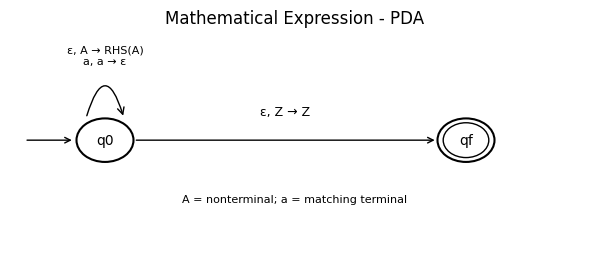

In [2]:
# MATHEMATICAL EXPRESSION - PDA DIAGRAM

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

fig, ax = plt.subplots(figsize=(6, 2.7))

ax.set_xlim(0, 6)
ax.set_ylim(0, 3)
ax.axis('off')

# STEP 1: Draw states

def draw_state(x, y, label, final=False):
    ax.add_patch(Circle((x, y), 0.30,
                        fill=False, linewidth=1.5))
    if final:
        ax.add_patch(Circle((x, y), 0.24,
                            fill=False, linewidth=1))
    ax.text(x, y, label, ha='center',
            va='center', fontsize=10)

draw_state(1, 1.5, 'q0')
draw_state(4.8, 1.5, 'qf', True)

# STEP 2: Initial arrow
ax.annotate('', xy=(0.68, 1.5), xytext=(0.15, 1.5),
            arrowprops=dict(arrowstyle='->'))

# STEP 3: Stack processing loop
loop = FancyArrowPatch(
    (0.8, 1.8), (1.2, 1.8),
    connectionstyle="arc3,rad=-1.7",
    arrowstyle='->',
    mutation_scale=12
)
ax.add_patch(loop)

ax.text(1, 2.55,
        'ε, A → RHS(A)\na, a → ε',
        ha='center', fontsize=8)

# STEP 4: Final transition
ax.annotate('', xy=(4.5, 1.5), xytext=(1.3, 1.5),
            arrowprops=dict(arrowstyle='->'))

ax.text(2.9, 1.85,
        'ε, Z → Z',
        ha='center', fontsize=9)

ax.text(3, 0.65,
        'A = nonterminal; a = matching terminal',
        ha='center', fontsize=8)

ax.set_title("Mathematical Expression - PDA", fontsize=12)

plt.tight_layout()
plt.show()

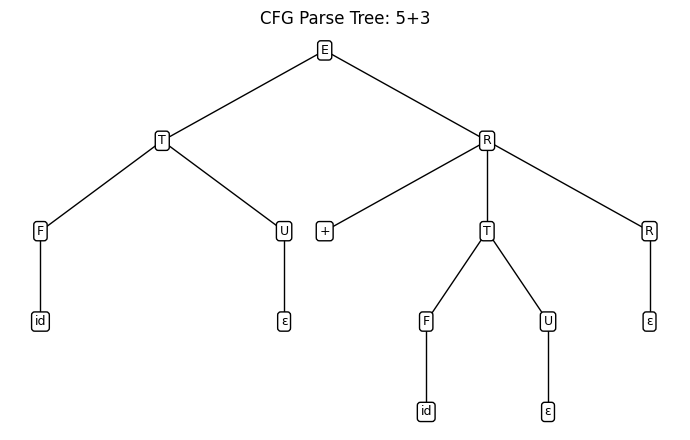

In [3]:
# MATHEMATICAL EXPRESSION - CFG PARSE TREE

import matplotlib.pyplot as plt

def expression_tree(expression):

    tokens = tokenize(expression)

    if tokens is None:
        print("Invalid expression.")
        return

    tokens.append('$')
    position = [0]

    nodes = []
    edges = []

    def add_node(label, parent=None):

        index = len(nodes)
        nodes.append(label)

        if parent is not None:
            edges.append((parent, index))

        return index

    def parse(symbol, parent=None):

        root = add_node(symbol, parent)
        lookahead = tokens[position[0]]

        rule = get_production(symbol, lookahead)

        if rule is None:
            raise ValueError("Invalid expression")

        if not rule:
            add_node("ε", root)
            return root

        for item in rule:

            if item in nonterminals:
                parse(item, root)

            else:
                add_node(item, root)
                position[0] += 1

        return root

    try:

        parse('E')

        if tokens[position[0]] != '$':
            raise ValueError("Extra input")

    except (ValueError, IndexError):
        print("Invalid expression. No parse tree.")
        return

    # STEP 1: Calculate node levels

    levels = {}

    def assign_levels(node, level):

        levels[node] = level

        children = [b for a, b in edges if a == node]

        for child in children:
            assign_levels(child, level + 1)

    assign_levels(0, 0)

    # STEP 2: Calculate horizontal positions

    positions = {}

    def place(node, x, width):

        positions[node] = (x, -levels[node])

        children = [b for a, b in edges if a == node]

        if children:

            gap = width / len(children)

            for i, child in enumerate(children):

                child_x = x - width/2 + gap*(i + 0.5)

                place(child, child_x, width/len(children)*1.5)

    place(0, 0, 8)

    # STEP 3: Draw parse tree

    fig, ax = plt.subplots(figsize=(7, 4.5))

    for a, b in edges:

        x1, y1 = positions[a]
        x2, y2 = positions[b]

        ax.plot([x1, x2], [y1, y2],
                'k-', linewidth=1)

    for i, label in enumerate(nodes):

        x, y = positions[i]

        ax.text(
            x, y, label,
            ha='center',
            va='center',
            fontsize=9,
            bbox=dict(boxstyle='round,pad=0.25',
                      fc='white', ec='black')
        )

    ax.set_title("CFG Parse Tree: " + expression)
    ax.axis('off')

    plt.tight_layout()
    plt.show()


expression_tree("5+3")